In [1]:
import os, sys

os.environ.setdefault("CORTEIDH_BASE", "C:/Users/USER/Desktop/proyectoPLN")
sys.path.append("clasificacion")
from comun import *
import numpy as np, pandas as pd


Conocer los datos


In [2]:
df, Y, etiquetas = cargar_articulos()
print(df.shape, Y.shape)

df.head(3)

(305, 27) (305, 15)


,doc_id,caso_id,titulo,estado,anio,tipo_sentencia,articulos,texto,lemas,num_palabras,...,art_17,art_19,art_21,art_22,art_23,art_24,art_25,art_26,temporal,particion
0,1034838366_sentencia,caso cuéllar sandoval y otros vs el salvador,caso cuéllar sandoval y otros vs. el salvador,el salvador,2024.0,fondo,"[3, 4, 5, 7, 8, 13, 16, 17, 19, 25]","En este capítulo, la Corte establecerá los hec...",capítulo corte establecer caso base reconocimi...,2900,...,1,1,0,0,0,0,1,0,prueba,1
1,1035032346_sentencia,caso aguirre magaña vs el salvador,caso aguirre magaña vs. el salvador,el salvador,2024.0,fondo,"[8, 25]",Conforme al reconocimiento de responsabilidad ...,conforme reconocimiento responsabilidad estado...,412,...,0,0,0,0,0,0,1,0,prueba,2
2,1039244171_sentencia,caso asociación civil memoria activa vs argentina,caso asociación civil memoria activa vs. argen...,argentina,2024.0,fondo,"[4, 5, 8, 13, 24, 25]","En este capítulo, la Corte establecerá los hec...",capítulo corte establecer caso base reconocimi...,7794,...,0,0,0,0,0,1,1,0,prueba,0


In [3]:
# Que tan frecuente es cada articulo

prevalencia = pd.Series(Y.mean(axis=0), index=etiquetas).sort_values(ascending=False)
prevalencia

#se ordenan de mas frecuente a menos frecuente

8     0.931148
25    0.793443
5     0.675410
4     0.445902
7     0.419672
13    0.206557
19    0.203279
11    0.186885
3     0.163934
26    0.150820
17    0.150820
24    0.137705
22    0.134426
21    0.127869
23    0.114754
dtype: float64

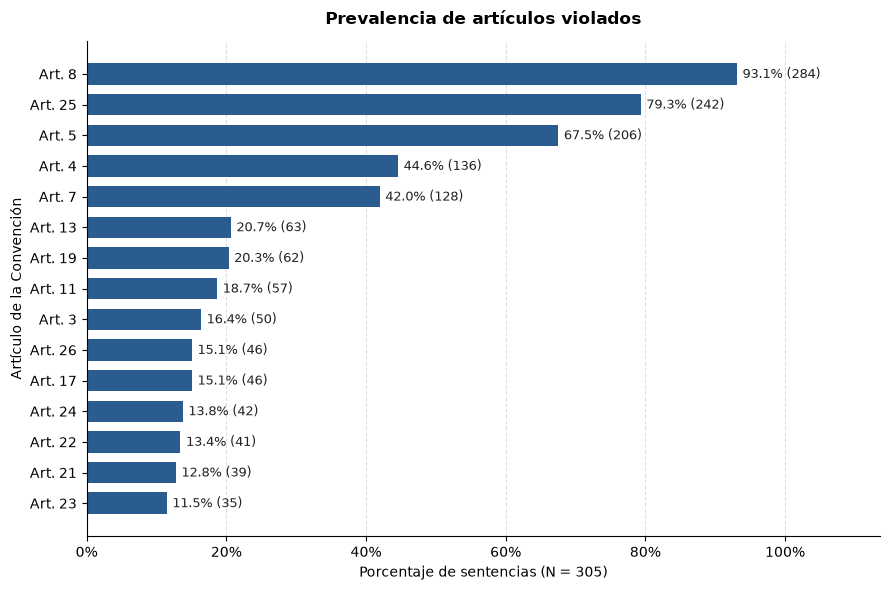

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Barras horizontales: el artículo más frecuente queda arriba.
prev = pd.Series(Y.mean(axis=0), index=etiquetas).sort_values()
conteos = pd.Series(Y.sum(axis=0), index=etiquetas).reindex(prev.index)

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(range(len(prev)), prev.values, color="#2b5c8f", height=0.7)
ax.set_yticks(range(len(prev)))
ax.set_yticklabels([f"Art. {a}" for a in prev.index])
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax.set_xlim(0, prev.max() * 1.22)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

for y, pct, n in zip(range(len(prev)), prev.values, conteos.values):
    ax.text(pct + 0.008, y, f"{pct:.1%} ({n})", va="center", ha="left",
            fontsize=9, color="#222222")

ax.set_xlabel(f"Porcentaje de sentencias (N = {len(Y)})")
ax.set_ylabel("Artículo de la Convención")
ax.set_title("Prevalencia de artículos violados", pad=12, fontweight="bold")
plt.tight_layout()
plt.show()


In [5]:
# Cuantos articulos tiene cada sentencia?
promedio_art_por_sentencia = Y.sum(axis=1).mean()
print(promedio_art_por_sentencia)

#Que tan largos son los hechos?
df['num_palabras'].describe()

4.842622950819672


count      305.000000
mean      5408.396721
std       3625.493539
min        412.000000
25%       2912.000000
50%       4562.000000
75%       6992.000000
max      31830.000000
Name: num_palabras, dtype: float64

In [6]:
# que articulos aparecen juntos? (matriz de co-ocurrencia)

co = pd.DataFrame(Y.T @ Y, index=etiquetas, columns=etiquetas)
co.style.background_gradient(cmap='Blues')

,3,4,5,7,8,11,13,17,19,21,22,23,24,25,26
3,50,42,48,44,48,17,17,20,17,7,13,3,8,46,2
4,42,136,131,74,130,31,33,35,48,14,25,6,20,120,19
5,48,131,206,113,194,53,46,46,62,20,36,13,30,175,30
7,44,74,113,128,125,42,30,28,28,15,20,7,20,105,13
8,48,130,194,125,284,55,58,45,58,36,39,34,40,233,41
11,17,31,53,42,55,57,17,20,22,13,15,5,20,48,13
13,17,33,46,30,58,17,63,22,23,10,18,15,14,52,16
17,20,35,46,28,45,20,22,46,36,8,24,3,8,40,8
19,17,48,62,28,58,22,23,36,62,11,25,6,10,54,11
21,7,14,20,15,36,13,10,8,11,39,10,8,4,35,11


In [7]:
import numpy as np
import pandas as pd

# Correlación phi entre columnas binarias.
# Se llena la diagonal antes de crear el DataFrame: en pandas 3, DataFrame.values
# puede ser de solo lectura y np.fill_diagonal(phi.values, np.nan) lanza ValueError.
matriz = np.corrcoef(Y, rowvar=False)
np.fill_diagonal(matriz, np.nan)
phi = pd.DataFrame(matriz, index=etiquetas, columns=etiquetas)

phi.style.background_gradient(cmap="coolwarm", vmin=-0.5, vmax=0.5).format("{:.2f}", na_rep="—")


,3,4,5,7,8,11,13,17,19,21,22,23,24,25,26
3,—,0.35,0.27,0.41,0.05,0.17,0.15,0.31,0.15,0.02,0.16,-0.08,0.03,0.14,-0.14
4,0.35,—,0.55,0.23,0.09,0.09,0.08,0.27,0.33,-0.07,0.13,-0.20,0.02,0.20,-0.03
5,0.27,0.55,—,0.38,0.06,0.26,0.06,0.29,0.35,-0.13,0.17,-0.23,0.03,0.20,-0.02
7,0.41,0.23,0.38,—,0.15,0.31,0.06,0.16,0.03,-0.03,0.05,-0.16,0.05,0.06,-0.12
8,0.05,0.09,0.06,0.15,—,0.06,-0.02,0.08,0.01,-0.01,0.03,0.06,0.03,0.25,-0.07
11,0.17,0.09,0.26,0.31,0.06,—,0.11,0.27,0.22,0.14,0.18,-0.04,0.30,0.06,0.10
13,0.15,0.08,0.06,0.06,-0.02,0.11,—,0.28,0.21,0.05,0.23,0.20,0.13,0.04,0.15
17,0.31,0.27,0.29,0.16,0.08,0.27,0.28,—,0.61,0.06,0.48,-0.07,0.04,0.08,0.03
19,0.15,0.33,0.35,0.03,0.01,0.22,0.21,0.61,—,0.07,0.40,-0.03,0.03,0.10,0.04
21,0.02,-0.07,-0.13,-0.03,-0.01,0.14,0.05,0.06,0.07,—,0.14,0.11,-0.04,0.10,0.14


In [8]:
# Cambian con el tiempo?
